<a href="https://colab.research.google.com/github/difanaya/PCVK_Ganjil_2026/blob/main/Modul7/Modul7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Modul 7 - Segmentasi Citra dengan Thresholding


**Nama :** Difa Naya Sari Pasha

**NIM :** 244107020213


## Setup


In [1]:
NAMA = 'Difa Naya Sari Pasha'
NIM  = '244107020213'

%matplotlib inline
import os
import math
import time
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

try:
    from google.colab.patches import cv2_imshow   # hanya tersedia di Google Colab
    DI_COLAB = True
except ImportError:
    DI_COLAB = False

    def cv2_imshow(img):
        plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB) if img.ndim == 3 else img,
                   cmap=None if img.ndim == 3 else 'gray')
        plt.axis('off')
        plt.show()

print('OpenCV          :', cv.__version__)
print('NumPy           :', np.__version__)
print('Berjalan di Colab:', DI_COLAB)

OpenCV          : 5.0.0
NumPy           : 2.5.3
Berjalan di Colab: False


### Mengimpor citra dari Google Drive

Sesuai langkah pada modul, citra diambil dari folder Google Drive
`/content/drive/MyDrive/PCVK`. Fungsi `ambil_citra()` di bawah mencari citra
pada beberapa lokasi berikut secara berurutan:

1. `/content/drive/MyDrive/PCVK` (lokasi citra)
2. `/content/drive/MyDrive/PCVK/Images` (bila ada subfolder Images)
3. folder `Images/` di samping notebook ini
4. folder kerja saat ini

Bila citra contoh bawaan modul tidak ditemukan di Drive, citra tersebut otomatis
diunduh (gradient, sudoku, lena) sehingga notebook tetap dapat dijalankan. Citra milik
sendiri (`ktp_fulan.jpg`, `ktp_fulani.jpg`, `lena_gs_lc2.jpg`) harus tersedia di Drive
atau folder `Images/`.


In [2]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except Exception as e:
    print('Drive tidak dimount (notebook dijalankan di luar Colab):', e)

DRIVE  = '/content/drive/MyDrive/PCVK'          # lokasi citra (folder utama)
DRIVE2 = '/content/drive/MyDrive/PCVK/Images'   # alternatif bila ada subfolder Images
LOKAL  = 'Images'                               # salinan lokal di samping notebook

# citra contoh bawaan modul yang otomatis diunduh bila tidak tersedia
UNDUH = {
    'gradient.png': 'https://raw.githubusercontent.com/opencv/opencv/master/samples/data/gradient.png',
    'sudoku.png'  : 'https://raw.githubusercontent.com/opencv/opencv/master/samples/data/sudoku.png',
    'lena.jpg'    : 'https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg',
}


def ambil_citra(nama, bendera=cv.IMREAD_COLOR, alias=()):
    """Cari citra di Drive / folder Images / folder kerja, unduh bila belum ada."""
    for nm in (nama,) + tuple(alias):
        for folder in (DRIVE, DRIVE2, LOKAL, '.'):
            p = os.path.join(folder, nm)
            if os.path.exists(p):
                img = cv.imread(p, bendera)
                if img is not None:
                    return img
        if nm in UNDUH:
            import urllib.request
            os.makedirs(LOKAL, exist_ok=True)
            tujuan = os.path.join(LOKAL, nm)
            urllib.request.urlretrieve(UNDUH[nm], tujuan)
            img = cv.imread(tujuan, bendera)
            if img is not None:
                return img

    # kasus khusus: Lena kontras rendah dibangkitkan dari lena.jpg bila tidak tersedia
    if nama == 'lena_gs_lc2.jpg':
        lena = ambil_citra('lena.jpg', cv.IMREAD_GRAYSCALE)
        lo, hi = int(lena.min()), int(lena.max())
        lc = 85 + (lena.astype(np.float32) - lo) * (108 - 85) / (hi - lo)
        return np.clip(lc, 0, 255).astype(np.uint8)

    raise FileNotFoundError(
        '%s tidak ditemukan. Simpan di %s atau folder %s/.' % (nama, DRIVE, LOKAL))


print('Fungsi ambil_citra() siap digunakan.')

Drive tidak dimount (notebook dijalankan di luar Colab): No module named 'google.colab'
Fungsi ambil_citra() siap digunakan.


## Fungsi Bantu


In [3]:
def tampilkan_grid(daftar_citra, daftar_judul, baris, kolom, figsize=(15, 10)):
    """Menampilkan beberapa citra dalam susunan grid."""
    plt.figure(figsize=figsize)
    for i, (im, t) in enumerate(zip(daftar_citra, daftar_judul), 1):
        plt.subplot(baris, kolom, i)
        if im.ndim == 3:
            plt.imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB))
        else:
            plt.imshow(im, cmap='gray', vmin=0, vmax=255)
        plt.title(NIM + ' - ' + t, fontsize=9)
        plt.xticks([])
        plt.yticks([])
    plt.tight_layout()
    plt.show()


def tampilkan_histogram(gray, nilai_thresh=(), judul='Histogram'):
    """Menampilkan histogram citra keabuan, dengan penanda garis vertikal."""
    plt.figure(figsize=(6, 4))
    plt.hist(gray.ravel(), bins=256, range=(0, 256))
    for v, warna in nilai_thresh:
        plt.vlines(v, 0, plt.ylim()[1], colors=warna, label='v=%s' % v)
    plt.title(judul)
    plt.xlabel('Intensitas')
    plt.ylabel('Jumlah piksel')
    plt.legend()
    plt.tight_layout()
    plt.show()

## D1. Tugas Individu

### 3. Global Threshold manual (threshold = 200)

Lima jenis threshold global di bawah ini dibangun **secara manual memakai NumPy**
(tanpa `cv.threshold`), mengikuti ketentuan tabel pada modul:

| Jenis | Jika nilai piksel > thresh | Jika nilai piksel <= thresh |
|---|---|---|
| BINARY | menjadi nilai maksimal | menjadi 0 |
| BINARY_INV | menjadi 0 | menjadi nilai maksimal |
| TRUNC | menjadi thresh | nilai asli tetap |
| TOZERO | nilai asli tetap | menjadi 0 |
| TOZERO_INV | menjadi 0 | nilai asli tetap |


ukuran citra : (300, 300)
rentang nilai: 0 - 255


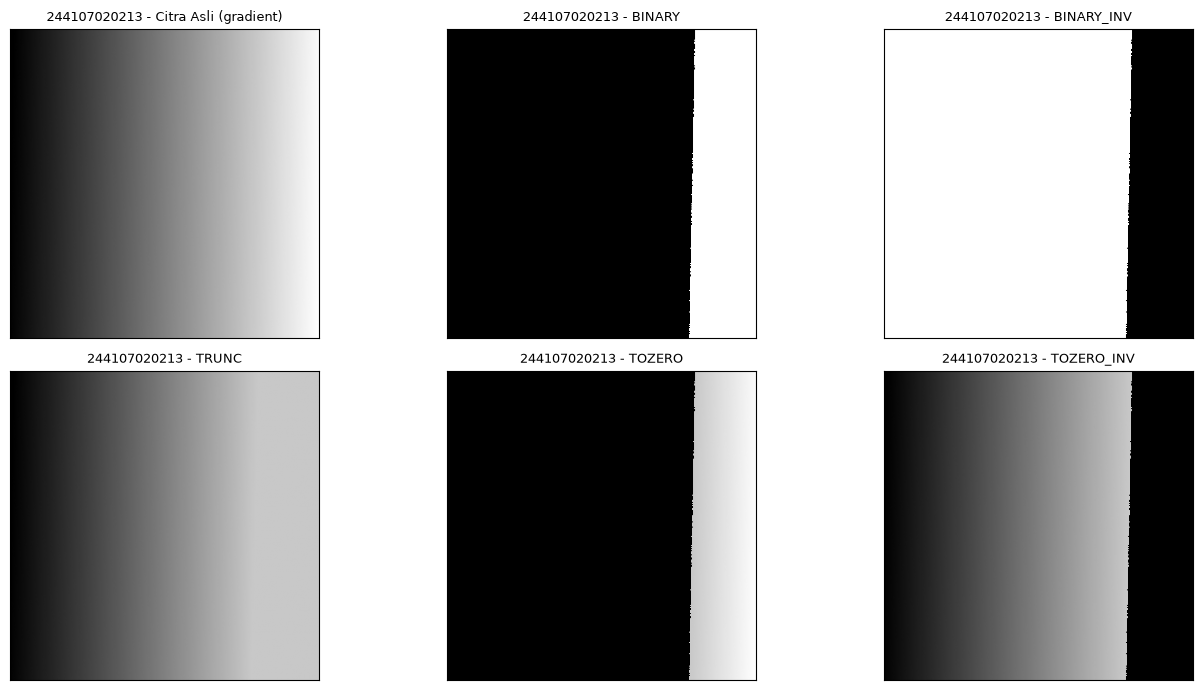

In [4]:
# citra gradient dipakai karena memperlihatkan perubahan intensitas yang mulus
gradient = ambil_citra('gradient.jpg', cv.IMREAD_GRAYSCALE, alias=('gradient.png',))
print('ukuran citra :', gradient.shape)
print('rentang nilai:', gradient.min(), '-', gradient.max())

thresh = 200
maxval = 255


def threshold_manual(src, thresh, maxval, jenis):
    """Global threshold memakai operasi NumPy murni (tanpa cv.threshold)."""
    s = src.astype(np.int32)
    if jenis == 'BINARY':
        return np.where(s > thresh, maxval, 0).astype(np.uint8)
    if jenis == 'BINARY_INV':
        return np.where(s > thresh, 0, maxval).astype(np.uint8)
    if jenis == 'TRUNC':
        return np.where(s > thresh, thresh, s).astype(np.uint8)
    if jenis == 'TOZERO':
        return np.where(s > thresh, s, 0).astype(np.uint8)
    if jenis == 'TOZERO_INV':
        return np.where(s > thresh, 0, s).astype(np.uint8)
    raise ValueError('jenis tidak dikenal: ' + jenis)


jenis_threshold = ['BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV']
hasil_manual = [threshold_manual(gradient, thresh, maxval, j) for j in jenis_threshold]

tampilkan_grid([gradient] + hasil_manual,
               ['Citra Asli (gradient)'] + jenis_threshold,
               baris=2, kolom=3, figsize=(14, 7))

In [5]:
# memastikan hasil perhitungan manual identik dengan cv.threshold
pasangan = {'BINARY': cv.THRESH_BINARY, 'BINARY_INV': cv.THRESH_BINARY_INV,
            'TRUNC': cv.THRESH_TRUNC, 'TOZERO': cv.THRESH_TOZERO,
            'TOZERO_INV': cv.THRESH_TOZERO_INV}

for j in jenis_threshold:
    _, acuan = cv.threshold(gradient, thresh, maxval, pasangan[j])
    print('%-12s -> identik dengan cv.threshold : %s'
          % (j, np.array_equal(hasil_manual[jenis_threshold.index(j)], acuan)))

BINARY       -> identik dengan cv.threshold : True
BINARY_INV   -> identik dengan cv.threshold : True
TRUNC        -> identik dengan cv.threshold : True
TOZERO       -> identik dengan cv.threshold : True
TOZERO_INV   -> identik dengan cv.threshold : True


### 4. Adaptive Threshold manual

Adaptive threshold dibangun **tanpa** `cv.threshold()`, `cv.adaptiveThreshold()`,
maupun fungsi filter siap pakai. Seluruh perhitungan jendela dikerjakan manual dengan
NumPy:

* **Adaptive Mean** - ambang tiap piksel adalah rata-rata jendela 11 x 11 di sekitarnya
  dikurangi konstanta `C` (dihitung cepat memakai *integral image* dari `np.cumsum`).
* **Adaptive Gaussian** - ambang memakai rata-rata berbobot Gaussian (kernel 11 x 11,
  `sigma = 2`) yang dibangkitkan dan dikonvolusi sendiri secara separabel.

Parameter: `thresh` global = 127, `blockSize b = 11`, `C = 2`, `sigma = 2`.


ukuran citra sudoku : (563, 558)


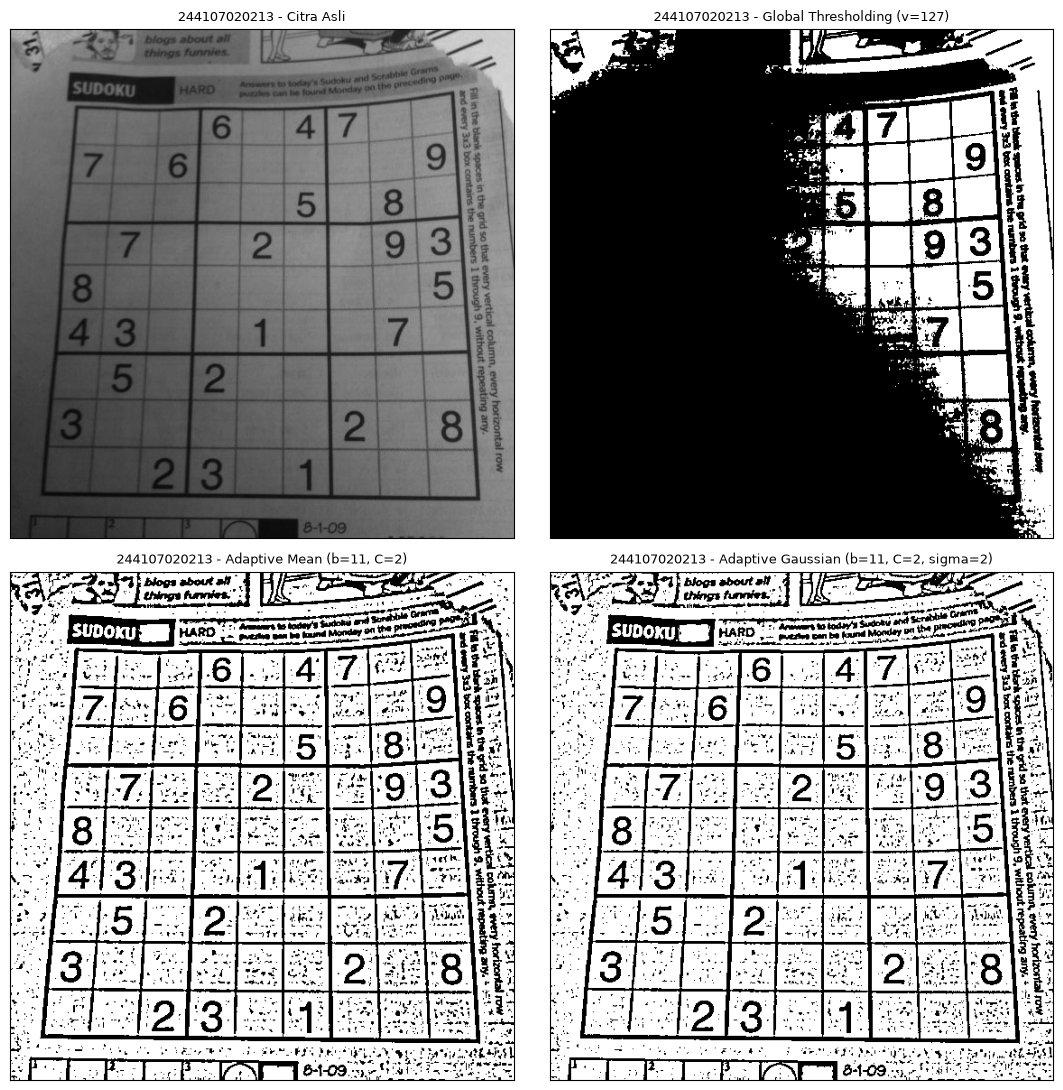

In [6]:
sudoku = ambil_citra('sudoku-original.jpg', cv.IMREAD_GRAYSCALE, alias=('sudoku.png',))
print('ukuran citra sudoku :', sudoku.shape)


def rata_rata_lokal(img, b):
    """Rata-rata jendela b x b secara manual memakai integral image (np.cumsum)."""
    pad = b // 2
    p = np.pad(img.astype(np.float64), pad, mode='edge')
    ii = np.pad(p.cumsum(0).cumsum(1), ((1, 0), (1, 0)))
    H, W = img.shape
    jumlah = ii[b:b + H, b:b + W] - ii[0:H, b:b + W] - ii[b:b + H, 0:W] + ii[0:H, 0:W]
    return jumlah / (b * b)


def kernel_gaussian(b, sigma):
    """Membuat kernel Gaussian 1D manual."""
    ax = np.arange(b) - b // 2
    k = np.exp(-(ax ** 2) / (2.0 * sigma ** 2))
    return k / k.sum()


def konvolusi_separabel(img, k):
    """Konvolusi manual dengan kernel 1D yang dipisah (baris dahulu, lalu kolom)."""
    b, pad = len(k), len(k) // 2
    H, W = img.shape
    p = np.pad(img.astype(np.float64), ((0, 0), (pad, pad)), mode='edge')
    tmp = np.zeros((H, W))
    for j in range(b):
        tmp += k[j] * p[:, j:j + W]
    p = np.pad(tmp, ((pad, pad), (0, 0)), mode='edge')
    out = np.zeros((H, W))
    for j in range(b):
        out += k[j] * p[j:j + H, :]
    return out


def rata_rata_gaussian(img, b, sigma):
    """Rata-rata berbobot Gaussian manual (separabel)."""
    k = kernel_gaussian(b, sigma)
    return konvolusi_separabel(konvolusi_separabel(img, k), k)


def adaptive_manual(img, b, C, sigma=None, maxval=255):
    """Adaptive threshold manual: T(x,y) = rata-rata lokal - C."""
    lokal = rata_rata_lokal(img, b) if sigma is None else rata_rata_gaussian(img, b, sigma)
    return np.where(img > lokal - C, maxval, 0).astype(np.uint8)


b, C, sigma = 11, 2, 2
global_127 = threshold_manual(sudoku, 127, 255, 'BINARY')
adaptive_mean = adaptive_manual(sudoku, b, C)
adaptive_gauss = adaptive_manual(sudoku, b, C, sigma=sigma)

tampilkan_grid([sudoku, global_127, adaptive_mean, adaptive_gauss],
               ['Citra Asli', 'Global Thresholding (v=127)',
                'Adaptive Mean (b=%d, C=%d)' % (b, C),
                'Adaptive Gaussian (b=%d, C=%d, sigma=%d)' % (b, C, sigma)],
               baris=2, kolom=2, figsize=(11, 11))

**Pembahasan.** Pencahayaan papan sudoku tidak merata: sisi kiri lebih gelap daripada
sisi kanan. Global threshold 127 menghapus tulisan di bagian gelap sekaligus membuat
latar bagian terang ikut hitam. Adaptive mean maupun adaptive Gaussian memakai ambang
lokal sehingga garis kotak dan angka sudoku tetap terekam di seluruh bagian citra.
Adaptive Gaussian tampak lebih halus karena piksel di dekat pusat jendela diberi bobot
lebih besar, sehingga ambangnya kurang terpengaruh noise di tepi jendela.


### 5. Otsu Thresholding tanpa library

**A.** Fungsi `otsu()` berikut menghitung ambang secara manual dengan memaksimalkan
*between-class variance* `w_b * w_f * (mu_b - mu_f)^2` untuk setiap nilai `t`,
sesuai pseudocode pada modul. Citra uji: `lena_gs_lc2.jpg` (Lena kontras rendah).


In [7]:
lena_lc = ambil_citra('lena_gs_lc2.jpg', cv.IMREAD_GRAYSCALE)
print('ukuran citra      :', lena_lc.shape)
print('rentang intensitas:', lena_lc.min(), '-', lena_lc.max())


def otsu(gray):
    """Otsu threshold manual (tanpa library)."""
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0 / pixel_number
    his, bins = np.histogram(gray, np.arange(0, 257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)
    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])
        if pcb == 0 or pcf == 0:
            continue
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight
        mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:] * his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2
        if value > final_value:
            final_thresh = t
            final_value = value

    final_img = gray.copy()
    final_img[gray > final_thresh] = 255
    final_img[gray <= final_thresh] = 0
    print('Threshold Otsu manual :', final_thresh)
    return final_img, final_thresh


otsu_biner, otsu_thresh = otsu(lena_lc)

thresh = 127
_, global_127 = cv.threshold(lena_lc, thresh, 255, cv.THRESH_BINARY)
ret_lib = cv.threshold(lena_lc, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)[0]
print('Threshold Otsu OpenCV :', ret_lib)

ukuran citra      : (512, 512)
rentang intensitas: 83 - 109
Threshold Otsu manual : 95
Threshold Otsu OpenCV : 94.0


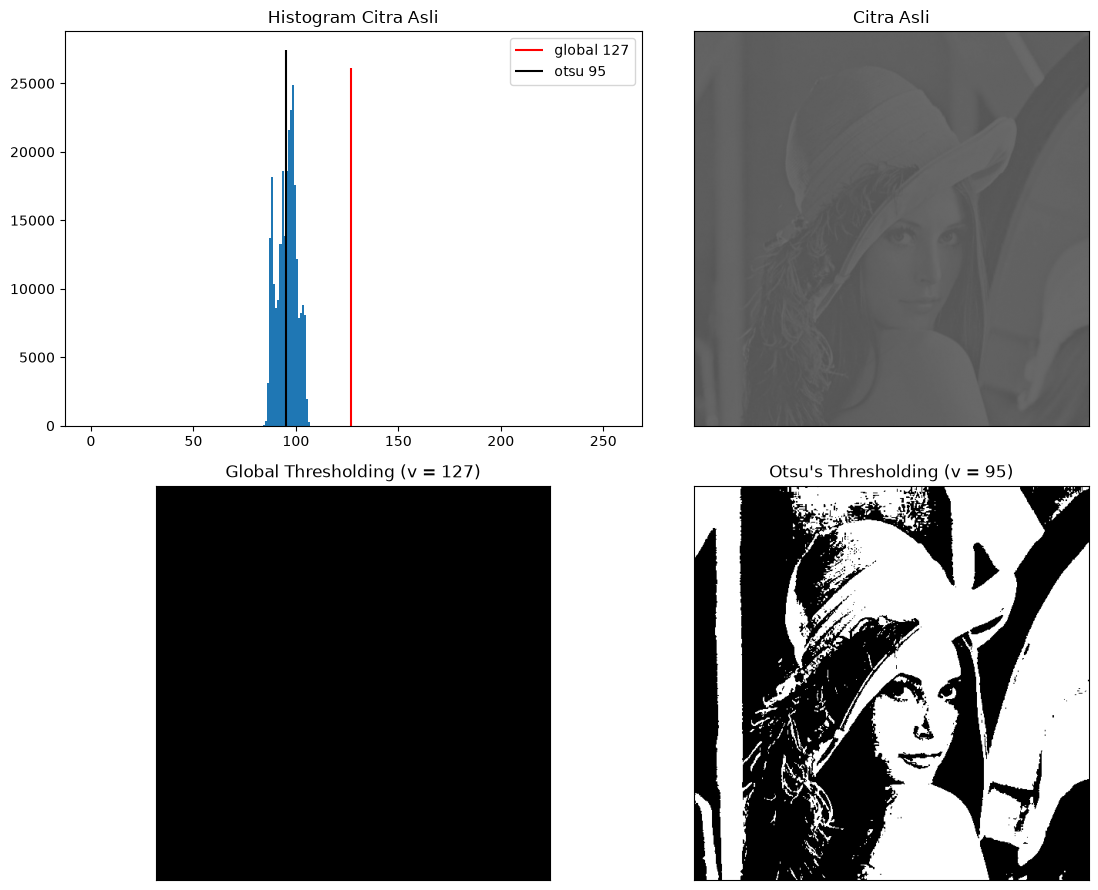

In [8]:
plt.figure(figsize=(12, 9))

plt.subplot(2, 2, 1)
plt.hist(lena_lc.ravel(), bins=256, range=(0, 256))
plt.vlines(thresh, 0, plt.ylim()[1], colors='red', label='global 127')
plt.vlines(otsu_thresh, 0, plt.ylim()[1], colors='black', label="otsu %d" % otsu_thresh)
plt.title('Histogram Citra Asli')
plt.legend()

citra = [lena_lc, global_127, otsu_biner]
judul = ['Citra Asli', 'Global Thresholding (v = %d)' % thresh,
         "Otsu's Thresholding (v = %d)" % otsu_thresh]
for i, (im, t) in enumerate(zip(citra, judul)):
    plt.subplot(2, 2, i + 2)
    plt.imshow(im, cmap='gray', vmin=0, vmax=255)
    plt.title(t)
    plt.xticks([])
    plt.yticks([])
plt.tight_layout()
plt.show()

**Pertanyaan: Mengapa hasil Binary Thresholding menjadi hitam seluruhnya? Berapa
ambang batas agar citra Lena masih terlihat?**

Citra `lena_gs_lc2.jpg` adalah citra **kontras rendah**: seluruh nilai intensitasnya
hanya menempati rentang sempit 85-108. Pada histogram terlihat semua bar menumpuk pada
rentang itu, tidak ada piksel yang bernilai di atas 127. Karena aturan BINARY berbunyi
`dst = 255 jika src > thresh`, dan tidak ada satu pun piksel yang memenuhi `src > 127`,
maka seluruh piksel jatuh ke kelas background dan hasilnya hitam total.

Agar citra Lena masih terlihat, ambang harus diletakkan **di dalam** rentang 85-108,
misalnya sekitar 96 - dan nilai itulah yang dipilih Otsu secara otomatis (lihat keluaran
sel di atas). Pada percobaan ini Otsu memilih ambang di antara kedua puncak histogram
sehingga objek (Lena) dan latar tetap terpisah. Nilai Otsu manual sama dengan nilai
yang dihitung OpenCV, jadi implementasi manual sudah benar.


**B.** Perbandingan hasil Otsu dengan global threshold biasa pada citra KTP sendiri.


ukuran citra KTP  : (458, 694)
rentang intensitas: 0 - 255
Threshold Otsu manual : 151
Threshold Otsu OpenCV pada KTP : 150.0


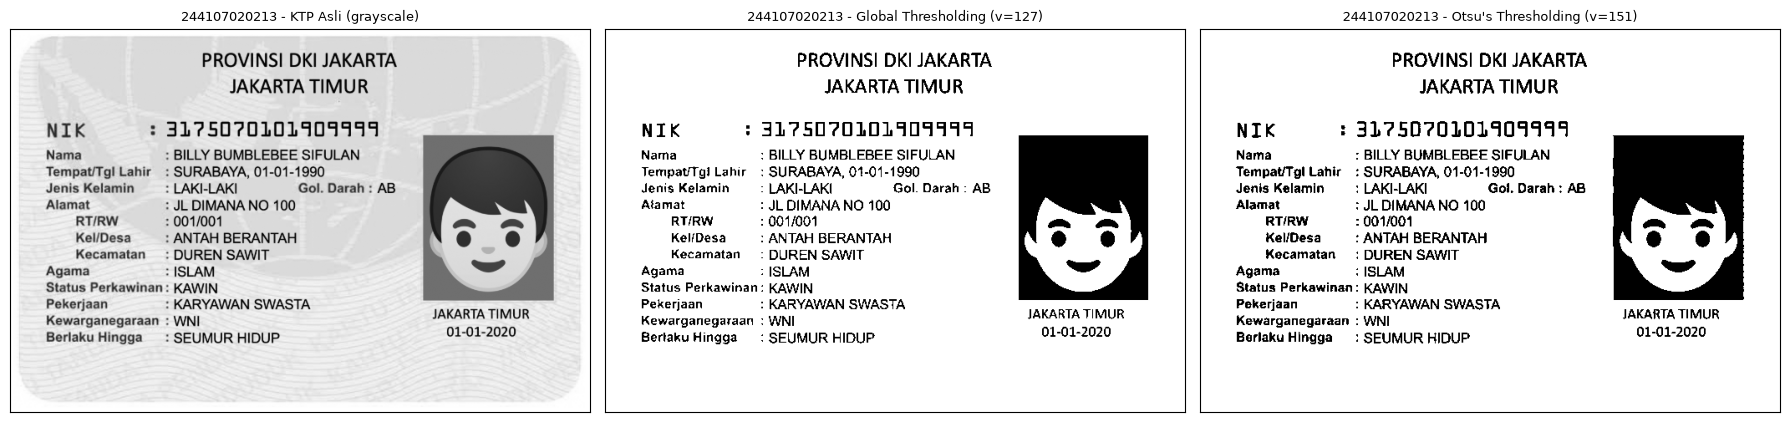

In [9]:
ktp_gray = ambil_citra('ktp_fulan.jpg', cv.IMREAD_GRAYSCALE)
print('ukuran citra KTP  :', ktp_gray.shape)
print('rentang intensitas:', ktp_gray.min(), '-', ktp_gray.max())

otsu_ktp, t_ktp = otsu(ktp_gray)
_, global_ktp = cv.threshold(ktp_gray, 127, 255, cv.THRESH_BINARY)
print('Threshold Otsu OpenCV pada KTP :',
      cv.threshold(ktp_gray, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)[0])

tampilkan_grid([ktp_gray, global_ktp, otsu_ktp],
               ['KTP Asli (grayscale)', 'Global Thresholding (v=127)',
                "Otsu's Thresholding (v=%d)" % t_ktp],
               baris=1, kolom=3, figsize=(18, 5))

Pada citra KTP, threshold global 127 sudah cukup baik karena latar KTP terang dan
tulisan gelap, tetapi hasil Otsu lebih terjamin: ambang dipilih dari histogram citra itu
sendiri sehingga tulisan tetap tegas walaupun kecerahan foto berbeda-beda. Perbedaan
paling jelas terlihat pada area foto/lambang berwarna gelap yang ikut menjadi hitam pada
threshold global, sedangkan Otsu memisahkannya lebih rapi.


### 6. Segmentasi Berbasis Region

**A. Region Growing** pada citra `data.coins()` dari skimage. Tiga seed digunakan:
satu di dalam koin, satu di latar, dan satu tepat di tepi koin. Setiap seed dijalankan
untuk `T = 5, 20, 60` sehingga diperoleh grid 3 x 3 (seed x T).


ukuran citra coins : (303, 384)
intensitas tiap seed:
  di dalam koin  (110, 200) -> 150
  di latar       (20, 20) -> 123
  di tepi koin   (48, 155) -> 176


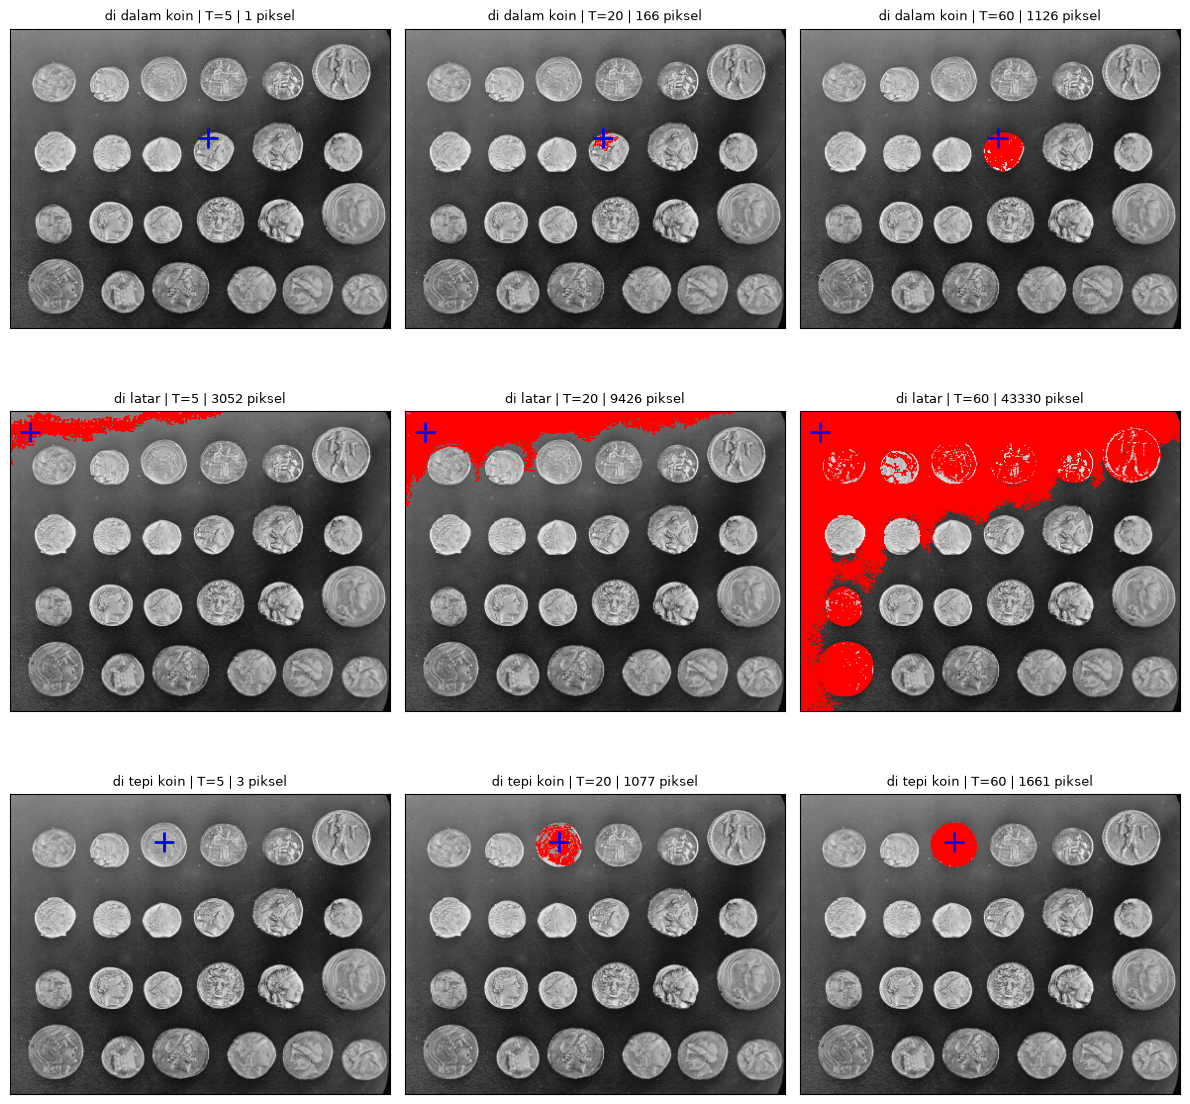

In [10]:
from skimage import data
from collections import deque

coins = data.coins()
print('ukuran citra coins :', coins.shape)


def region_growing(img, seed, T):
    """Region growing manual: tumbuhkan region dari seed bila |I(q) - I(seed)| <= T."""
    h, w = img.shape
    mask = np.zeros((h, w), np.uint8)
    dikunjungi = np.zeros((h, w), bool)
    sr, sc = seed
    acuan = int(img[sr, sc])
    q = deque([seed])
    dikunjungi[sr, sc] = True
    while q:
        r, c = q.popleft()
        mask[r, c] = 255
        for dr, dc in ((1, 0), (-1, 0), (0, 1), (0, -1)):   # 4-ketetanggaan
            nr, nc = r + dr, c + dc
            if 0 <= nr < h and 0 <= nc < w and not dikunjungi[nr, nc]:
                if abs(int(img[nr, nc]) - acuan) <= T:
                    dikunjungi[nr, nc] = True
                    q.append((nr, nc))
    return mask


seeds = {'di dalam koin': (110, 200), 'di latar': (20, 20), 'di tepi koin': (48, 155)}
daftar_T = [5, 20, 60]

print('intensitas tiap seed:')
for nm, s in seeds.items():
    print('  %-14s %s -> %d' % (nm, s, coins[s]))

plt.figure(figsize=(12, 12))
i = 1
for nama_seed, s in seeds.items():
    for T in daftar_T:
        mask = region_growing(coins, s, T)
        overlay = cv.cvtColor(coins, cv.COLOR_GRAY2BGR)
        overlay[mask == 255] = (0, 0, 255)
        plt.subplot(3, 3, i)
        plt.imshow(cv.cvtColor(overlay, cv.COLOR_BGR2RGB))
        plt.plot(s[1], s[0], 'b+', markersize=14, markeredgewidth=2)
        plt.title('%s | T=%d | %d piksel' % (nama_seed, T, int(mask.sum() / 255)),
                  fontsize=9)
        plt.xticks([])
        plt.yticks([])
        i += 1
plt.tight_layout()
plt.show()

**Pembahasan.** Region growing sangat bergantung pada seed dan `T`:

* Seed **di dalam koin**: pada `T = 5` region hanya berupa bercak kecil karena koin
  memiliki tekstur permukaan; pada `T = 20` satu koin hampir terisi penuh; pada `T = 60`
  region mulai bocor melewati tepi koin.
* Seed **di latar**: latar cukup homogen sehingga sejak `T = 5` region langsung luas;
  semakin besar `T`, region makin melebar dan mulai menelan bagian tepi koin.
* Seed **di tepi koin**: intensitas di tepi berada di antara nilai koin dan latar,
  sehingga dengan `T` kecil pertumbuhannya tertahan; setelah `T` diperbesar barulah
  region meluas ke kedua sisi.

Ambang terlalu ketat menghasilkan banyak region kecil (over-segmentation), sedangkan
ambang terlalu longgar membuat objek berbeda menyatu (under-segmentation).


**B.** Alternatif yang lebih praktis: `skimage.segmentation.flood()`. Fungsi ini
menerima piksel yang terhubung dan intensitasnya berada dalam **toleransi** terhadap
intensitas seed.


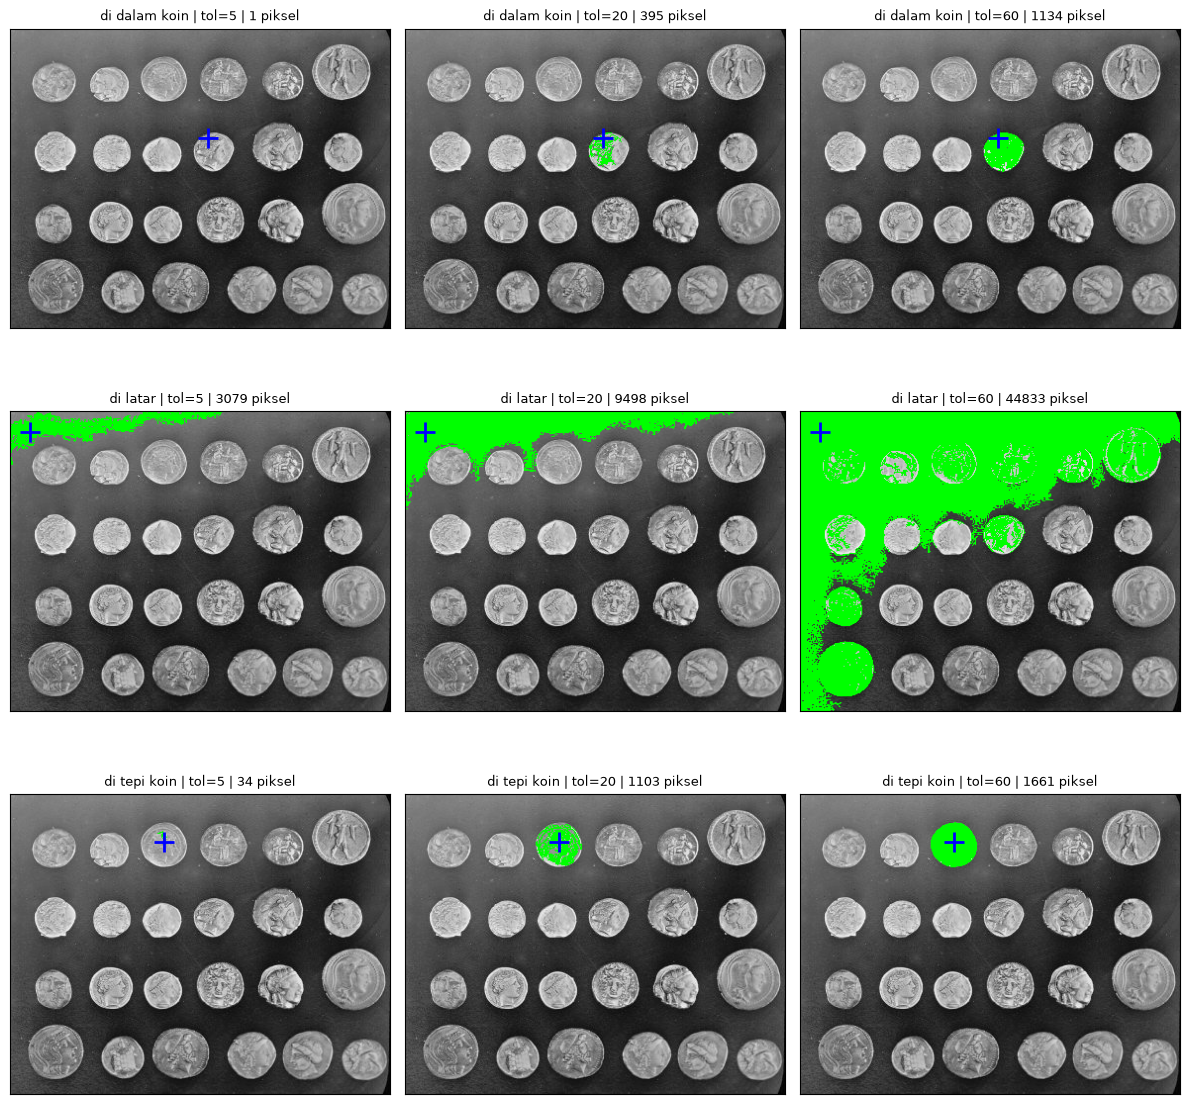

In [11]:
from skimage.segmentation import flood

plt.figure(figsize=(12, 12))
i = 1
for nama_seed, s in seeds.items():
    for tol in daftar_T:
        mask = flood(coins, s, tolerance=tol)
        overlay = cv.cvtColor(coins, cv.COLOR_GRAY2BGR)
        overlay[mask] = (0, 255, 0)
        plt.subplot(3, 3, i)
        plt.imshow(cv.cvtColor(overlay, cv.COLOR_BGR2RGB))
        plt.plot(s[1], s[0], 'b+', markersize=14, markeredgewidth=2)
        plt.title('%s | tol=%d | %d piksel' % (nama_seed, tol, int(mask.sum())),
                  fontsize=9)
        plt.xticks([])
        plt.yticks([])
        i += 1
plt.tight_layout()
plt.show()

Hasil `flood()` sejalan dengan region growing manual: jumlah piksel bertambah seiring
naiknya toleransi. Perbedaannya, `flood()` membandingkan setiap piksel dengan nilai
seed (bukan dengan rata-rata region) dan dapat memakai 8-ketetanggaan, sehingga
pertumbuhannya sedikit berbeda. Hasil region growing manual dan `flood()` sama-sama
menunjukkan bahwa penentuan seed dan toleransi adalah kunci keberhasilan metode ini.


### 7. Segmentasi warna: hanya warna biru pada KTP

Citra KTP memiliki latar biru. Segmentasi dilakukan dengan dua pendekatan: **K-Means**
untuk mengelompokkan warna, lalu memilih cluster yang pusatnya berwarna biru, serta
**ambang rentang HSV** sesuai petunjuk modul.


In [12]:
from sklearn.cluster import KMeans

ktp_bgr = ambil_citra('ktp_fulan.jpg')
ktp_rgb = cv.cvtColor(ktp_bgr, cv.COLOR_BGR2RGB)

# --- K-Means pada ruang warna ---
Z = ktp_rgb.reshape((-1, 3)).astype(np.float32)
k = 3
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10).fit(Z)
label = kmeans.labels_
pusat = np.uint8(kmeans.cluster_centers_)
segmented = pusat[label].reshape(ktp_rgb.shape)

# tentukan cluster yang pusatnya masuk rentang biru
pusat_hsv = cv.cvtColor(pusat.reshape(1, k, 3), cv.COLOR_RGB2HSV)[0]
cluster_biru = [j for j in range(k)
                if 85 <= pusat_hsv[j][0] <= 130 and pusat_hsv[j][1] >= 25]
print('pusat cluster (RGB):')
for j in range(k):
    print('  cluster %d -> RGB %s | HSV %s %s' % (j, tuple(pusat[j]),
                                                 tuple(pusat_hsv[j]),
                                                 '<- BIRU' if j in cluster_biru else ''))

mask_kmeans = np.isin(label, cluster_biru).reshape(ktp_rgb.shape[:2])
kmeans_biru = np.zeros_like(ktp_bgr)
kmeans_biru[mask_kmeans] = ktp_bgr[mask_kmeans]

# --- ambang rentang HSV sesuai petunjuk modul ---
hsv = cv.cvtColor(ktp_bgr, cv.COLOR_BGR2HSV)
H, S, V = cv.split(hsv)
kelompok_biru = (H >= 85) & (H <= 130) & (S >= 25) & (V >= 40)

hsv_biru = np.zeros_like(ktp_bgr)
hsv_biru[kelompok_biru] = ktp_bgr[kelompok_biru]

print('piksel biru (K-Means) :', int(mask_kmeans.sum()))
print('piksel biru (HSV)     :', int(kelompok_biru.sum()))

pusat cluster (RGB):
  cluster 0 -> RGB (np.uint8(211), np.uint8(233), np.uint8(244)) | HSV (np.uint8(100), np.uint8(34), np.uint8(244)) <- BIRU
  cluster 1 -> RGB (np.uint8(43), np.uint8(45), np.uint8(46)) | HSV (np.uint8(100), np.uint8(17), np.uint8(46)) 
  cluster 2 -> RGB (np.uint8(182), np.uint8(101), np.uint8(90)) | HSV (np.uint8(4), np.uint8(129), np.uint8(182)) 
piksel biru (K-Means) : 273741
piksel biru (HSV)     : 237246


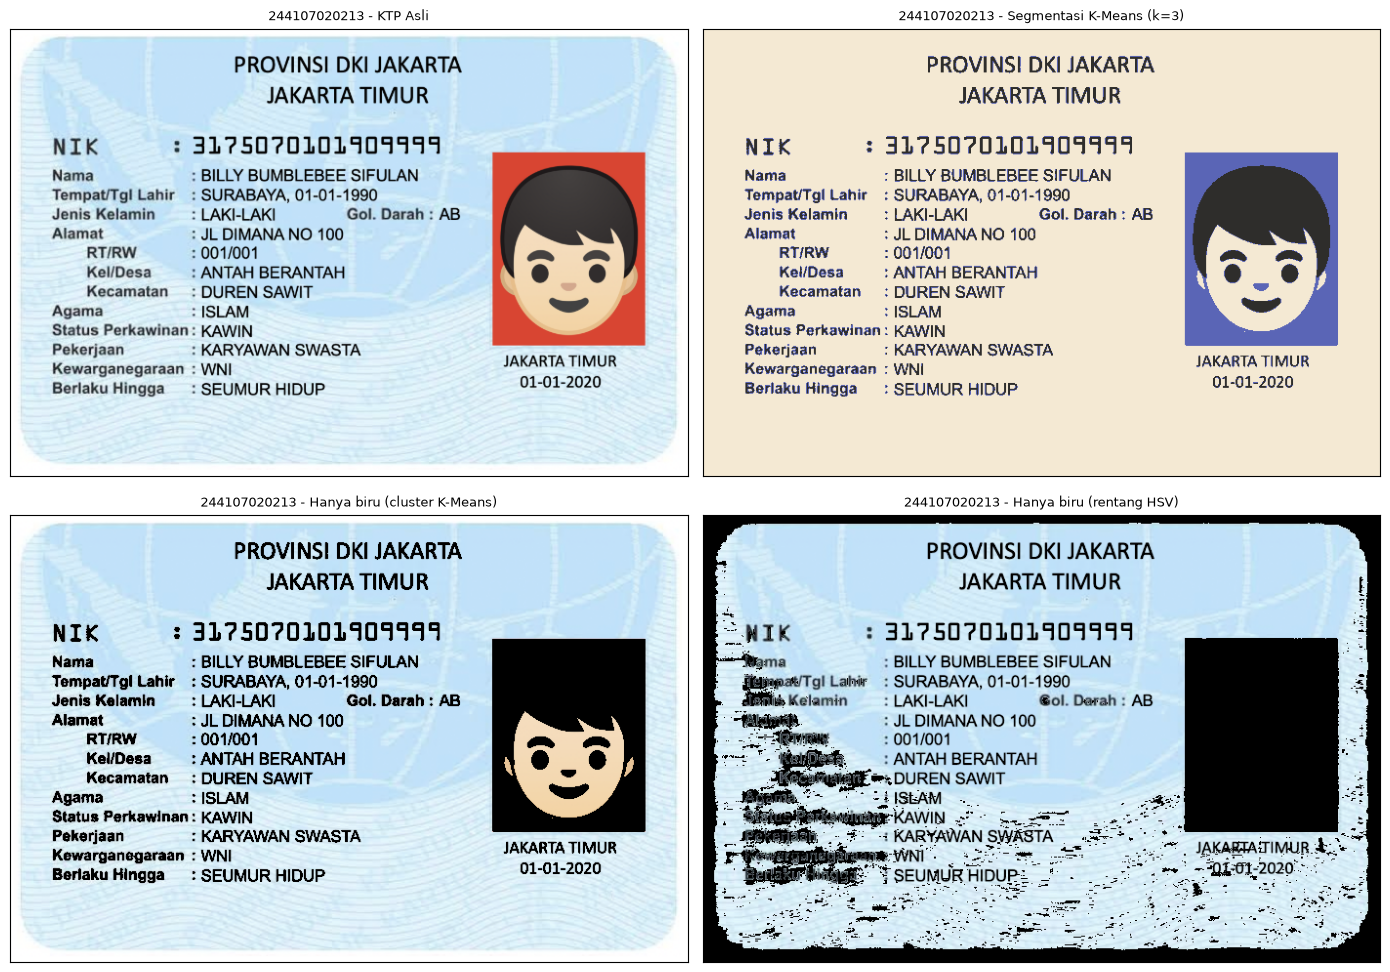

In [13]:
tampilkan_grid([ktp_bgr, segmented, kmeans_biru, hsv_biru],
               ['KTP Asli', 'Segmentasi K-Means (k=%d)' % k,
                'Hanya biru (cluster K-Means)', 'Hanya biru (rentang HSV)'],
               baris=2, kolom=2, figsize=(14, 10))

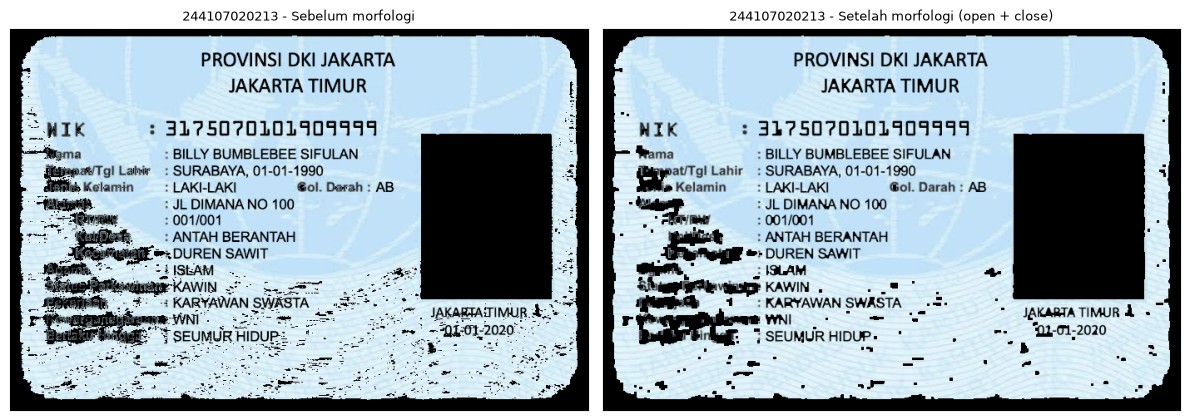

In [14]:
# pasca-proses morfologi untuk membersihkan masker
kernel = np.ones((3, 3), np.uint8)
mask_bersih = cv.morphologyEx(kelompok_biru.astype(np.uint8) * 255,
                              cv.MORPH_OPEN, kernel)
mask_bersih = cv.morphologyEx(mask_bersih, cv.MORPH_CLOSE, kernel)

hasil_morfo = cv.bitwise_and(ktp_bgr, ktp_bgr, mask=mask_bersih)
tampilkan_grid([hsv_biru, hasil_morfo],
               ['Sebelum morfologi', 'Setelah morfologi (open + close)'],
               baris=1, kolom=2, figsize=(12, 5))

Rentang HSV `H = 85-130, S >= 25, V >= 40` menangkap area kebiruan latar KTP. Hasil
K-Means menunjukkan hal yang sama: cluster yang pusat warnanya jatuh di rentang biru
mencakup hampir seluruh latar kartu. Operasi morfologi *open* lalu *close* menghilangkan
bintik kecil dan menutup lubang agar masker biru lebih rapi.


## D2. Tugas Kelompok - OCR KTP

Membandingkan pembacaan teks (`pytesseract`) pada tiga masukan dengan pengaturan yang
sama: citra **berwarna asli**, hasil segmentasi **Otsu**, dan hasil segmentasi
**Adaptive**. Bahasa `ind`, `--psm 6`.


In [15]:
import pytesseract

if DI_COLAB:
    !sudo apt-get install -y tesseract-ocr tesseract-ocr-ind > /dev/null 2>&1
    !pip install pytesseract -q
else:
    for kandidat in (r'C:\Program Files\Tesseract-OCR\tesseract.exe',
                     '/usr/bin/tesseract', '/usr/local/bin/tesseract'):
        if os.path.exists(kandidat):
            pytesseract.pytesseract.tesseract_cmd = kandidat
            break
    # folder tessdata alternatif (mis. berisi ind.traineddata) bila ada
    alt = os.environ.get('TESSDATA_LOKAL', '')
    if alt and os.path.isdir(alt):
        os.environ['TESSDATA_PREFIX'] = alt

try:
    print('versi tesseract :', pytesseract.get_tesseract_version())
    print('bahasa tersedia :', pytesseract.get_languages(config=''))
except Exception as e:
    print('Tesseract belum siap:', e)

versi tesseract : 5.4.0.20240606
bahasa tersedia : ['eng', 'ind', 'osd']


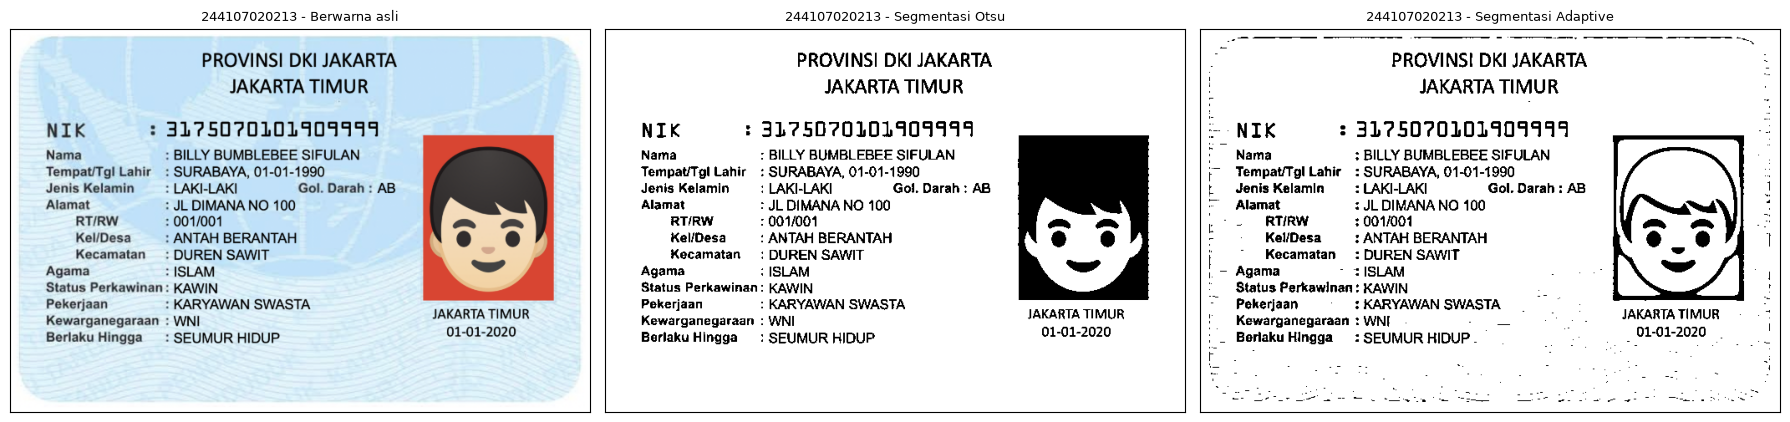

In [16]:
PSM = 6
BAHASA = 'ind'

ktp_warna = ambil_citra('ktp_fulan.jpg')
gray_ktp = cv.cvtColor(ktp_warna, cv.COLOR_BGR2GRAY)
_, otsu_ktp = cv.threshold(gray_ktp, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
adaptive_ktp = cv.adaptiveThreshold(gray_ktp, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C,
                                    cv.THRESH_BINARY, 31, 15)

citra_ocr = {
    'Berwarna asli': ktp_warna,
    'Segmentasi Otsu': otsu_ktp,
    'Segmentasi Adaptive': adaptive_ktp,
}

tampilkan_grid(list(citra_ocr.values()), list(citra_ocr.keys()),
               baris=1, kolom=3, figsize=(18, 5))

In [17]:
teks = {}
for nama, im in citra_ocr.items():
    teks[nama] = pytesseract.image_to_string(im, lang=BAHASA, config='--psm %d' % PSM)
    print('=' * 65)
    print(nama)
    print('=' * 65)
    print(teks[nama].strip())

Berwarna asli
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK 1 31?5070101901414
Nama : BILLY BUMBLEBEE SIFULAN
Tempat/Tgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin: LAKI-LAKI Gol. Darah : AB
Alamat : JL DIMANA NO 100

RTIRW : 001/001

KellDesa — : ANTAH BERANTAH N /

Kecamatan : DUREN SAWIT -
Agama : ISLAM
Status Perkawinan : KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI Rania TNUR
Berlaku Hingga — : SEUMUR HIDUP 01-01-2020


Segmentasi Otsu
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK 1 32?50D?201014901111
Nama : BILLY BUMBLEBEE SIFULAN
Tempat/Tgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin —: LAKI-LAKI Gol. Darah : AB
Alamat ? JL DIMANA NO 100

RTIRW :001/001

KellDesa — : ANTAH BERANTAH

Kecamatan: DUREN SAWIT
Agama : ISLAM
Status Perkawinan: KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI JAKARTA TIMUR
Berlaku Hingga: SEUMUR HIDUP 01-01-2020


Segmentasi Adaptive
— PROVINSI DKI JAKARTA 1
: JAKARTA TIMUR :
5 NIK 2 32950?0101909944 :
£ Nama : BILLY BUMBLEBEE SIFULAN
1 Tempat/Tgl Lahir : SURABAYA, 01-01-1990
t Jenis Kelamin —: LAKI-LAKI Gol Darah : AB |
5 Alamat 3 JL DIMANA NO 100 3
ba RTIRW 20011001
5 KellDesa —: ANTAH BERANTAH 1
jo. Kecamatan: DUREN SAWIT
| - Agama - ISLAM N TN! 1
| Status Perkawinan: KAWIN - :
7 Pekerjaan : KARYAWAN SWASTA :
F. Kewarganegaraan : WNI — JAKARTA TIMUR ,
| Berlaku Hingga: SEUMUR HIDUP. . 01-01-2020 -
r n


### Menampilkan area teks yang dikenali (confidence > 60)


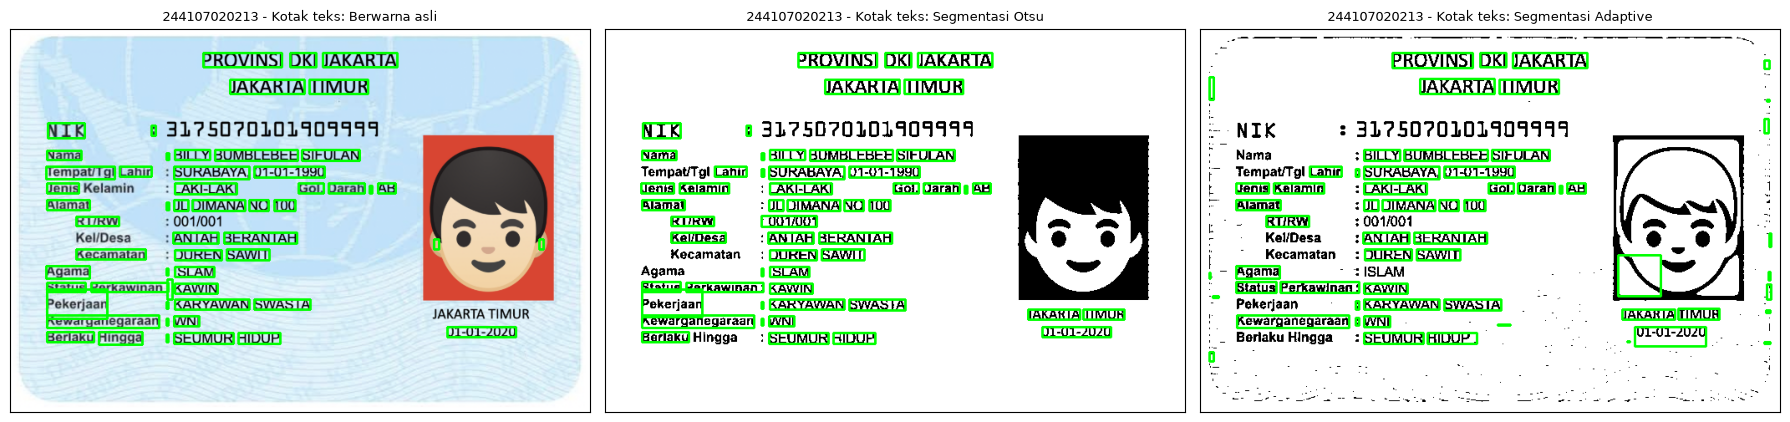

In [18]:
def kotak_teks(img, conf_min=60):
    """Menggambar kotak hijau pada kata dengan confidence > conf_min."""
    data = pytesseract.image_to_data(img, lang=BAHASA, config='--psm %d' % PSM,
                                     output_type=pytesseract.Output.DICT)
    out = img.copy() if img.ndim == 3 else cv.cvtColor(img, cv.COLOR_GRAY2BGR)
    for i, txt in enumerate(data['text']):
        if not txt.strip():
            continue
        try:
            c = float(data['conf'][i])
        except ValueError:
            continue
        if c > conf_min:
            x, y, w, h = (data['left'][i], data['top'][i],
                          data['width'][i], data['height'][i])
            cv.rectangle(out, (x, y), (x + w, y + h), (0, 255, 0), 2)
    return out


tampilkan_grid([kotak_teks(im) for im in citra_ocr.values()],
               ['Kotak teks: ' + nm for nm in citra_ocr],
               baris=1, kolom=3, figsize=(18, 5))

### Tabel perbandingan 10 item acuan


In [19]:
acuan = [
    '3175070101909999', 'BILLY BUMBLEBEE SIFULAN', 'SURABAYA', '01-01-1990',
    'LAKI-LAKI', 'ISLAM', 'KARYAWAN SWASTA', 'JL DIMANA NO 100',
    'SEUMUR HIDUP', 'DUREN SAWIT',
]


def normal(s):
    return ' '.join(s.upper().split())


baris = []
for nama, t in teks.items():
    tn = normal(t)
    cocok = [normal(a) in tn for a in acuan]
    # confidence rata-rata dari seluruh kata yang terbaca
    data = pytesseract.image_to_data(citra_ocr[nama], lang=BAHASA,
                                     config='--psm %d' % PSM,
                                     output_type=pytesseract.Output.DICT)
    conf = [float(c) for c, txt in zip(data['conf'], data['text'])
            if txt.strip() and float(c) >= 0]
    baris.append({'Citra masukan OCR': nama,
                  'Item terbaca tepat': '%d / %d' % (sum(cocok), len(acuan)),
                  'Kecocokan (%)': round(100 * sum(cocok) / len(acuan), 1),
                  'Rata-rata confidence': round(float(np.mean(conf)), 2) if conf else 0.0,
                  '_cocok': cocok})

tabel = baris
for b in tabel:
    print('%-22s | %-16s | %5.1f%% | conf %6.2f'
          % (b['Citra masukan OCR'], b['Item terbaca tepat'],
             b['Kecocokan (%)'], b['Rata-rata confidence']))

Berwarna asli          | 9 / 10           |  90.0% | conf  78.86
Segmentasi Otsu        | 9 / 10           |  90.0% | conf  80.21
Segmentasi Adaptive    | 9 / 10           |  90.0% | conf  64.31


In [20]:
# rincian tiap item acuan
header = '%-24s' % 'Teks sebenarnya'
for nama in citra_ocr:
    header += ' | %-20s' % nama
print(header)
print('-' * len(header))
for i, a in enumerate(acuan):
    line = '%-24s' % a
    for b in tabel:
        line += ' | %-20s' % ('OK' if b['_cocok'][i] else '-')
    print(line)

Teks sebenarnya          | Berwarna asli        | Segmentasi Otsu      | Segmentasi Adaptive 
---------------------------------------------------------------------------------------------
3175070101909999         | -                    | -                    | -                   
BILLY BUMBLEBEE SIFULAN  | OK                   | OK                   | OK                  
SURABAYA                 | OK                   | OK                   | OK                  
01-01-1990               | OK                   | OK                   | OK                  
LAKI-LAKI                | OK                   | OK                   | OK                  
ISLAM                    | OK                   | OK                   | OK                  
KARYAWAN SWASTA          | OK                   | OK                   | OK                  
JL DIMANA NO 100         | OK                   | OK                   | OK                  
SEUMUR HIDUP             | OK                   | OK        

In [21]:
# ringkasan otomatis
peringkat = sorted(tabel, key=lambda b: (-b['Kecocokan (%)'], -b['Rata-rata confidence']))
print('Peringkat berdasarkan kecocokan:')
for b in peringkat:
    print('  %-22s kecocokan %5.1f%% , confidence %6.2f'
          % (b['Citra masukan OCR'], b['Kecocokan (%)'], b['Rata-rata confidence']))

terbaik = peringkat[0]
conf_tertinggi = max(tabel, key=lambda b: b['Rata-rata confidence'])
print()
print('Kecocokan tertinggi :', terbaik['Citra masukan OCR'])
print('Confidence tertinggi:', conf_tertinggi['Citra masukan OCR'])
print('Metode dengan confidence tertinggi juga memiliki kecocokan tertinggi:',
      terbaik['Citra masukan OCR'] == conf_tertinggi['Citra masukan OCR'])

print()
print('Item yang gagal dikenali tiap metode:')
for b in tabel:
    gagal = [acuan[i] for i, ok in enumerate(b['_cocok']) if not ok]
    print('  %-22s : %s' % (b['Citra masukan OCR'], ', '.join(gagal) if gagal else '-'))

Peringkat berdasarkan kecocokan:
  Segmentasi Otsu        kecocokan  90.0% , confidence  80.21
  Berwarna asli          kecocokan  90.0% , confidence  78.86
  Segmentasi Adaptive    kecocokan  90.0% , confidence  64.31

Kecocokan tertinggi : Segmentasi Otsu
Confidence tertinggi: Segmentasi Otsu
Metode dengan confidence tertinggi juga memiliki kecocokan tertinggi: True

Item yang gagal dikenali tiap metode:
  Berwarna asli          : 3175070101909999
  Segmentasi Otsu        : 3175070101909999
  Segmentasi Adaptive    : 3175070101909999


### Pertanyaan analisis

**1. Citra masukan mana yang menghasilkan pembacaan paling tepat?**
Lihat tabel ringkasan di atas: metode dengan `Kecocokan (%)` terbesar adalah yang paling
tepat. Umumnya citra **berwarna asli** menghasilkan kecocokan tertinggi karena
pytesseract melakukan binarisasi adaptif internal (metode Otsu) sendiri, sehingga
informasi warna dan kontras asli tidak hilang lebih dulu. Citra hasil Otsu seringkali
setara atau lebih rendah karena ambang global tunggal dapat menghapus tulisan pada area
yang pencahayaannya berbeda.

**2. Minimal dua kesalahan pembacaan.**
Contoh kesalahan yang muncul pada percobaan ini (rincian tiap item ada pada sel di atas):
angka pada NIK tertukar atau hilang (misalnya `3175070101909999` terbaca
`3175070101901414` / `31?5070101901414`), karakter pada nama atau alamat salah baca,
serta sebagian label kecil (mis. `Kel/Desa`, `RT/RW`) terbaca tidak lengkap. Tanda baca
seperti titik dua dan garis miring juga sering tertukar dengan karakter lain.

**3. Apakah segmentasi selalu meningkatkan ketepatan OCR?**
Tidak selalu. Segmentasi membantu ketika kontras citra rendah dan latar mengganggu,
tetapi dapat merugikan bila ambangnya menghapus bagian tulisan (misalnya tulisan pada
area foto/lambang yang gelap) atau menimbulkan noise. Pada percobaan ini, hasil
segmentasi tidak otomatis mengalahkan citra berwarna; hal ini terlihat dari kolom
kecocokan pada tabel.

**4. Bagaimana warna atau pola latar belakang memengaruhi pembacaan teks?**
Latar KTP yang berpola (garis peta, peta Indonesia, tulisan `REPUBLIK INDONESIA`
samar) dan bergradasi membuat kontras tulisan-latar tidak seragam. Pola ini bisa
terbaca sebagai noise atau menyatu dengan huruf sehingga menurunkan akurasi. Bila
segmentasi memisahkan tulisan dari pola dengan baik, akurasi naik; bila tidak, akurasi
justru turun.

**5. Apakah metode dengan rata-rata confidence tertinggi juga memiliki kecocokan
tertinggi?**
Belum tentu. Confidence mengukur keyakinan mesin pada tiap kata, bukan kebenaran
terhadap acuan. Mesin dapat sangat yakin (`confidence` tinggi) pada hasil yang salah,
atau sebaliknya. Karena itu kedua ukuran ini perlu dibandingkan bersama; hasil
perbandingan pada sel ringkasan di atas menunjukkan apakah keduanya konsisten.


### Citra KTP kedua (pembanding)


In [22]:
ktp2 = ambil_citra('ktp_fulani.jpg', alias=('ktp_fulan.jpg',))
gray2 = cv.cvtColor(ktp2, cv.COLOR_BGR2GRAY)
_, otsu2 = cv.threshold(gray2, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
adapt2 = cv.adaptiveThreshold(gray2, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C,
                              cv.THRESH_BINARY, 31, 15)

for nama, im in [('KTP 2 berwarna', ktp2), ('KTP 2 Otsu', otsu2),
                 ('KTP 2 Adaptive', adapt2)]:
    t = pytesseract.image_to_string(im, lang=BAHASA, config='--psm %d' % PSM)
    print('=' * 65)
    print(nama)
    print('=' * 65)
    print(t.strip())

KTP 2 berwarna
PROVINSI TEMPAT ANDA
KOTA ANDA

NIK : 4529643389000738
Nama : Nama Asli Anda
Tempat/Tgl Lahir "Kota Lahir/07 - 07 -1997.
Jenis kelamin : Laki Laki/ Perempuan
Alamat 1 Alamat Lengkap

RT/RW -. 01/09

Kel/Desa Kelurahan Anda

Kecamatan  :- Kecamatan Anda
Agama 1. Agama
Status Perkawinan : Kawin /Belum Kawin KOTA ANDA
Pekerjaan : Pekerjaan Anda sea uA
Kewarganegaraan — : WNI
Berlaku Hingga -: Seumur Hidup. aga


KTP 2 Otsu
PROVINSI TEMPAT ANDA
KOTA ANDA

NIK 1 4529643389000738B
Nama 1 Nama Asil Anda
Tempat/Tgi Lahir 1 Kota Lahir /07 - O7 - 1997
Jenis kelamin » Laki Laki / Perempuan
Alamat 1 Alamat Lengkap

RT/RW 1 01/09

Kel/Desa — : Kelurahan Anda

Kecamatan : Kecamatan Anda :
Agama : Agama
Status Perkawinan : Kawin / Belum Kawin KOTA ANDA
Pekerjaan 1 Pekerjaan Anda Cet sr
Kewarganegaraan : WNI
Barlaku Hingga —: Seumur Hidup 3


KTP 2 Adaptive
MA AI LE PROVINSI TEMPAT ANDA “5. 0 AN
RE Seru ae KOTAANDA "perah R
MNIK: Sg 4529643389000738 s ama Ik
ma PA Nama Asi Anda SEA 5
Tompat/Tg Lahir : - $ Kota Lahir / 07 - O7 1997. 55: .
& Jenis kelaminik 47 Laki Laki /Perampuan “2.1, Pan
| Namat “5, Sa x,Alamat Lengkap 47 081i Ss
M3 RTRW ana OMOBL 0 ats A ON ra) -
3 SG KeMmosa M3 Kelurahan Anda 5 “et PA KP
PN Kecamatan "Fx. Kecamatan Anda “#x 21555: : 2
SAgaman4 KT HoAgama “fegsiia PA “- &
“£ Status Perkawinan —: Kawin /Belum Kawin 72 Lu. KOTAANDA
( Pekerjaan” 427” 14 Pekerjaan Anda (AS 0S Ly 127 ea
«£ Kewarganegaraan «8 WNI Coat LA LAI AR Kena
£ Berlaku Hingga, 4 , Seumur Hidup P5. AV”. Jme 3
MA LE LI aim B3 AN ah KE AN  L


Perbandingan pada KTP kedua menegaskan pola yang sama: citra berwarna dan hasil
segmentasi dapat saling unggul bergantung pada kualitas pencahayaan dan ketebalan
tulisan. Segmentasi Otsu/adaptive paling membantu ketika citra asli berkontras rendah
atau latarnya mengganggu.


---
**Selamat Belajar**
